In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

  Transaction_ID        Date Customer_ID        Category        Product  \
0         T00001  2025-04-13        C146          Beauty    Moisturizer   
1         T00002  2025-12-15        C450          Beauty      Sunscreen   
2         T00003  2025-09-28        C112  Home & Kitchen        Toaster   
3         T00004  2025-04-17        C475          Sports  Running Shoes   
4         T00005  2025-03-13        C307          Beauty        Perfume   

   Quantity  Unit_Price  Total_Amount  
0         3      150000        450000  
1         2       90000        180000  
2         1      300000        300000  
3         3      700000       2100000  
4         2      400000        800000  

=== 2. INFORMASI & STRUKTUR DATA (INFO) ===
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Transaction_ID  2000 non-null   str  
 1   Date            2000 non-null   str

C:\Users\Faiz\AppData\Local\Temp\ipykernel_5284\3275909534.py:33: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
C:\Users\Faiz\AppData\Local\Temp\ipykernel_5284\3275909534.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


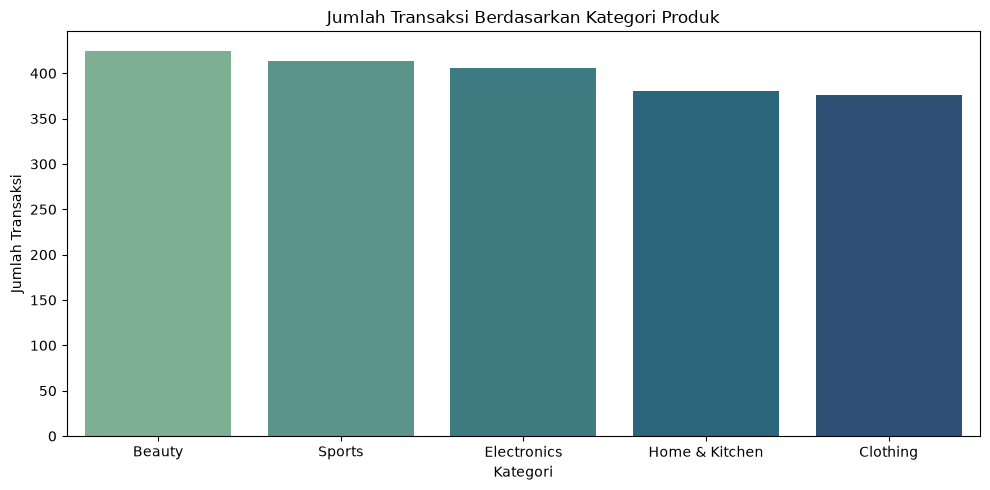

C:\Users\Faiz\AppData\Local\Temp\ipykernel_5284\3275909534.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


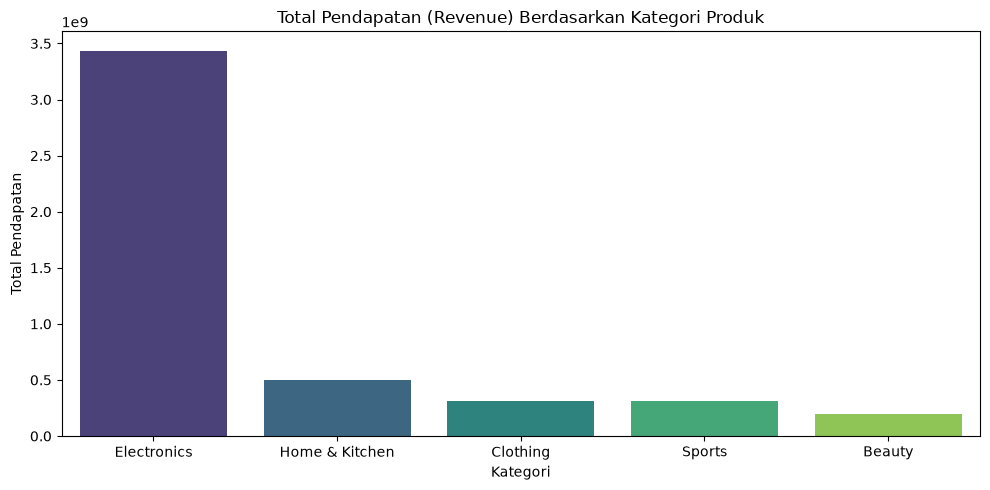

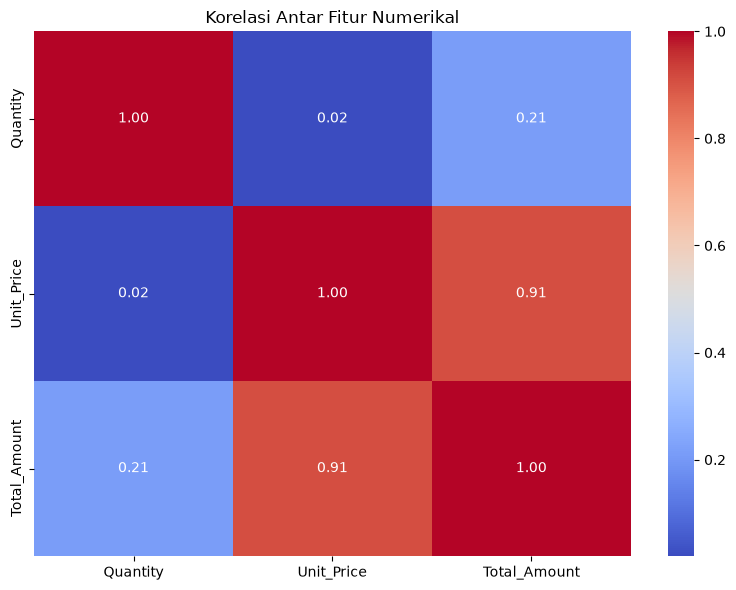

=== EKSPLORASI DATA SELESAI ===


In [2]:
file_path = 'retail sales.csv'
df = pd.read_csv(file_path)

# Menampilkan 5 baris pertama
print(df.head())

# ==========================================
# 2. INFORMASI & STRUKTUR DATA
# ==========================================
print('\n=== 2. INFORMASI & STRUKTUR DATA (INFO) ===')
df.info()

print('\n=== 3. STATISTIK DESKRIPTIF ===')
print(df.describe())

# ==========================================
# 3. PENGECEKAN DATA KOSONG (NULL) & DUPLIKAT
# ==========================================
print('\n=== 4. PENGECEKAN NULL & DUPLIKAT ===')
print('Jumlah data null/kosong tiap kolom:')
print(df.isnull().sum())

print(f'\nTotal baris duplikat: {df.duplicated().sum()}')

# Penanganan data kosong & duplikat (jika ada)
df = df.dropna()
df = df.drop_duplicates()

# ==========================================
# 4. PEMBAGIAN JENIS DATA (KATEGORIKAL & NUMERIKAL)
# ==========================================
print('\n=== 5. KLASIFIKASI JENIS DATA ===')
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()

print(f'Data Kategorikal (Objek/Teks): {categorical_cols}')
print(f'Data Numerikal (Angka): {numerical_cols}')

# ==========================================
# 5. EKSPLORASI DATA LANJUTAN & VISUALISASI
# ==========================================
print('\n=== 6. MENAMPILKAN EKSPLORASI & VISUALISASI DATA ===')

# Distribusi kategori produk
print('\nDistribusi Berdasarkan Kategori Produk:')
print(df['Category'].value_counts())

# Visualisasi 1: Jumlah Transaksi Berdasarkan Kategori Produk
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df, x='Category', order=df['Category'].value_counts().index, palette='crest'
)
plt.title('Jumlah Transaksi Berdasarkan Kategori Produk')
plt.xlabel('Kategori')
plt.ylabel('Jumlah Transaksi')
plt.tight_layout()
plt.show()

# Visualisasi 2: Total Pendapatan (*Total Amount*) Berdasarkan Kategori
category_sales = df.groupby('Category')['Total_Amount'].sum().reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(
    data=category_sales,
    x='Category',
    y='Total_Amount',
    order=category_sales.sort_values('Total_Amount', ascending=False)[
        'Category'
    ],
    palette='viridis',
)
plt.title('Total Pendapatan (Revenue) Berdasarkan Kategori Produk')
plt.xlabel('Kategori')
plt.ylabel('Total Pendapatan')
plt.tight_layout()
plt.show()

# Visualisasi 3: Korelasi Antar Fitur Numerikal
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.select_dtypes(include=[np.number]).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
)
plt.title('Korelasi Antar Fitur Numerikal')
plt.tight_layout()
plt.show()

print('=== EKSPLORASI DATA SELESAI ===')